# Clean all the features after location-based enrichment and store

This section includes pre-processing, and some analysis of conflicting rows after pre-processing (identical rows that differ in target values), and how we handle them later.

## Pre-processing the features 

- RENT_APPROVAL_DATE: Split into APPROVAL_YEAR and APPROVAL_MONTH, both numerical features.
- TOWN, STREET, HDB_SUBZONE, HDB_PLANNING_AREA, FLAT_TYPE, FLAT_MODEL: Normalize.
- FURNISHED, FEE: Remove.
- LOCATION_KEY: Derived from Town, street, block. Normalise.
- LEASE_COMMENCE_DATE, FLOOR_AREA_SQM, HDB_LATITUDE, HDB_LONGITUDE, HDB_YEAR_COMPLETED, NEAREST_MRT_KM, NEAREST_SCHOOL_KM, NEAREST_MALL_KM: Keep as is.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path.cwd()
PLOTS_DIR = PROJECT_ROOT / "plots"

sns.set_theme(style="whitegrid", context="paper", palette="husl")

train = pd.read_csv("derived/train_location_enriched.csv", dtype={"BLOCK": "string"}).dropna()
test = pd.read_csv("derived/test_location_enriched.csv", dtype={"BLOCK": "string"})

Drop the rows from train data that had NAN values in the completion year column.

In [2]:
def clean_categories(X):
    result = X.copy()
    for col in result.columns:
        values = (result[col].astype("string").str.strip().str.lower())
        values = values.str.replace(r"\s+", " ", regex=True)
        if col.strip().upper() == "FLAT_TYPE":
            values = values.str.replace(
                r"^(\d+)\s*[- ]\s*room$",
                r"\1-room",
                regex=True
            )
        result[col] = (
            values
            .fillna("<missing>")
            .replace("", "<missing>")
            .astype(object)
        )
    return result

def clean_all_features(data, is_train = True):
    """Build target-independent features while preserving input row order."""

    # clean categorical features - all capital, remove extra spaces, and replace missing values with "<MISSING>"
    categorical_columns = [
        "TOWN", 
        "STREET", 
        "FLAT_TYPE", 
        "FLAT_MODEL", 
        "HDB_SUBZONE", 
        "HDB_PLANNING_AREA", 
        "LOCATION_KEY"
        ]
    X = clean_categories(data[categorical_columns])

    dates = pd.to_datetime(data["RENT_APPROVAL_DATE"], format="%Y-%m", errors="raise")

    numeric_columns = [
        "FLOOR_AREA_SQM", 
        "LEASE_COMMENCE_DATE", 
        "HDB_LATITUDE", 
        "HDB_LONGITUDE", 
        "HDB_YEAR_COMPLETED", 
        "NEAREST_MRT_KM", 
        "NEAREST_SCHOOL_KM", 
        "NEAREST_MALL_KM"
        ]
    for col in numeric_columns:
        X[col] = pd.to_numeric(data[col], errors="coerce").astype(float)

    # split the RENT_APPROVAL_DATE into year and month
    # and create a month index relative to Jan 2021
    X["RENT_APPROVAL_DATE"] = dates
    X["APPROVAL_YEAR"] = dates.dt.year
    X["APPROVAL_MONTH"] = dates.dt.month
    X["MONTH_INDEX"] = (dates.dt.year - 2021) * 12 + dates.dt.month - 1
    X["BUILDING_AGE"] = dates.dt.year - X["LEASE_COMMENCE_DATE"]

    if is_train:
        X["MONTHLY_RENT"] = data["MONTHLY_RENT"]

    return X

In [3]:
cleaned_train = clean_all_features(train, True)
cleaned_test = clean_all_features(test, False)

cleaned_train.to_csv("derived/train_cleaned_enriched.csv", index=False)
cleaned_test.to_csv("derived/test_cleaned_enriched.csv", index=False)

## Conflicting entries: identical recorded features with different rents

From the cleaned data, group-by every non-target column. We may have different rents for identical recorded characteristics. This is not necessarily inconsistent, becasue unit identifier is not provided so we don't know if it is the same physical apartment. Right now, we don't deduplicate, average, or remove these rows. We just keep it for future analysis.

In [4]:
CONFLICT_TARGET = "MONTHLY_RENT"
CONFLICT_FEATURES = [c for c in cleaned_train.columns if c != CONFLICT_TARGET]

def list_rent_conflicts(data):
    keys = data[CONFLICT_FEATURES].copy()
    group_id = keys.groupby(CONFLICT_FEATURES, dropna=False, sort=False).ngroup()

    rows = data.copy()
    rows.insert(0, "Source_row", data.index)
    rows.insert(0, "Conflict_group", group_id.to_numpy())

    summary = rows.groupby("Conflict_group")[CONFLICT_TARGET].agg(
        Rows="size", Distinct_rents="nunique", Min_rent="min", Max_rent="max",
        Rents=lambda values: sorted(values.unique().tolist()),
    )
    summary["Rent_spread"] = summary["Max_rent"] - summary["Min_rent"]
    summary = summary.loc[summary["Distinct_rents"] > 1].sort_values(
        ["Rent_spread", "Rows"], ascending=False
    )

    # Attach identifying feature values to the group summary.
    representatives = rows.drop_duplicates("Conflict_group").set_index("Conflict_group")
    summary = summary.join(representatives[CONFLICT_FEATURES])
    entries = rows.loc[rows["Conflict_group"].isin(summary.index)].copy()
    entries = entries.join(summary[["Rent_spread", "Distinct_rents"]], on="Conflict_group")
    entries = entries.sort_values(
        ["Rent_spread", "Conflict_group", CONFLICT_TARGET],
        ascending=[False, True, True],
    )
    return summary, entries


conflict_summary, conflict_rows = list_rent_conflicts(cleaned_train)

In [5]:
conflict_summary.head()

,Rows,Distinct_rents,Min_rent,Max_rent,Rents,Rent_spread,TOWN,STREET,FLAT_TYPE,FLAT_MODEL,...,HDB_LONGITUDE,HDB_YEAR_COMPLETED,NEAREST_MRT_KM,NEAREST_SCHOOL_KM,NEAREST_MALL_KM,RENT_APPROVAL_DATE,APPROVAL_YEAR,APPROVAL_MONTH,MONTH_INDEX,BUILDING_AGE
Conflict_group,,,,,,,,,,,,,,,,,,,,,
73623,3,3,1500,5200,"[1500, 5000, 5200]",3700,central,cantonment road,4-room,type s1,...,103.841667,2009.0,0.392047,0.290172,0.484265,2023-06-01,2023,6,29,12.0
103401,3,3,950,4500,"[950, 1300, 4500]",3550,jurong west,jurong west street 61,5-room,improved,...,103.697940,2000.0,0.176878,0.197838,0.643089,2024-06-01,2024,6,41,22.0
82157,2,2,1800,5300,"[1800, 5300]",3500,bukit merah,telok blangah street 31,4-room,model a,...,103.807093,2017.0,0.778391,0.247727,0.748077,2023-09-01,2023,9,32,5.0
73232,2,2,600,3800,"[600, 3800]",3200,clementi,clementi avenue 2,4-room,new generation,...,103.770192,1977.0,0.551177,0.295239,0.646340,2023-06-01,2023,6,29,45.0
73002,2,2,1300,4300,"[1300, 4300]",3000,jurong west,jurong west street 64,5-room,premium apartment,...,103.704701,1999.0,0.333927,0.319646,0.831445,2023-06-01,2023,6,29,23.0


In [6]:
print(f"Total conflicting rows: {len(conflict_rows)}, number of conflict groups: {len(conflict_summary)}")

Total conflicting rows: 39469, number of conflict groups: 17869


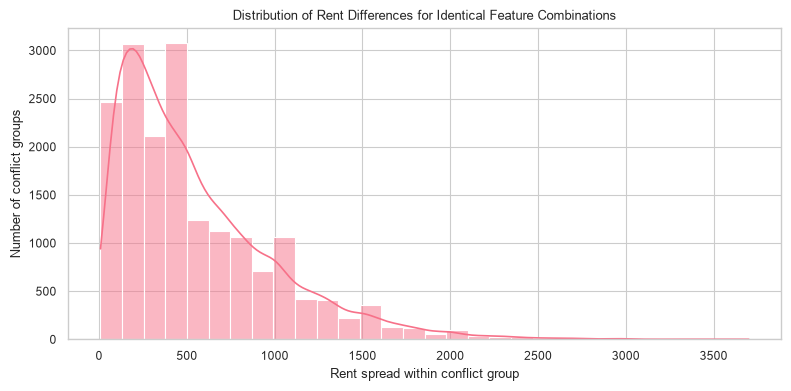

<Figure size 640x480 with 0 Axes>

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=conflict_summary,
    x="Rent_spread",
    bins=30,
    kde=True
)
plt.xlabel("Rent spread within conflict group")
plt.ylabel("Number of conflict groups")
plt.title("Distribution of Rent Differences for Identical Feature Combinations")
plt.tight_layout()
plt.show()
plt.savefig(PLOTS_DIR / "rent_spread_distribution.png", dpi=300, bbox_inches="tight")

From these insights, we can see that there are many rows that have exact same features but different target values. But the spread is not very large for most of the rows (0 - 1000). This indicates two things:

- The data might be incomplete. Since we don't have unit numbers, the different rents might be valid entries of different units.
- Erroneous data. Some entries might be wrong, and possibly outliers. Later, we review the model performance by adding some processing to make the conflicting rows consistent.